Formula 1 Pit Stop Strategy — OpenF1 Data Collection & Visualizations

Case study: 2024 Italian Grand Prix (Monza)

Questions: How do tire age and compound relate to lap times? What happens around pit stops? How can these observations inform pit-window decisions?

Source: https://openf1.org/docs/

1. Setup and data acquisition

Install missing packages if necessary: %pip install pandas numpy requests matplotlib seaborn.

In [12]:
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
BASE_URL = "https://api.openf1.org/v1"
YEAR = 2024
CIRCUIT = "Monza"

def fetch(endpoint, params):
    response = requests.get(f"{BASE_URL}/{endpoint}", params=params, timeout=90)
    response.raise_for_status()
    return pd.DataFrame(response.json())

sessions = fetch("sessions", {"year": YEAR, "session_name": "Race"})
matching = sessions[sessions["circuit_short_name"].astype(str).str.contains(CIRCUIT, case=False, na=False)]
if matching.empty:
    raise ValueError(f"No race session found for {YEAR} {CIRCUIT}")
session_key = int(matching.iloc[0]["session_key"])
print("Selected session key:", session_key)
display(matching)

laps_raw = fetch("laps", {"session_key": session_key})
stints_raw = fetch("stints", {"session_key": session_key})
pits_raw = fetch("pit", {"session_key": session_key})
print("Downloaded rows — laps:", len(laps_raw), "stints:", len(stints_raw), "pits:", len(pits_raw))
display(laps_raw.head(3))

Selected session key: 9590


,session_key,session_type,session_name,date_start,date_end,meeting_key,circuit_key,circuit_short_name,country_key,country_code,country_name,location,gmt_offset,year,is_cancelled
15,9590,Race,Race,2024-09-01T13:00:00+00:00,2024-09-01T15:00:00+00:00,1244,39,Monza,13,ITA,Italy,Monza,02:00:00,2024,False


Downloaded rows — laps: 1009 stints: 50 pits: 30


,meeting_key,session_key,driver_number,lap_number,date_start,duration_sector_1,duration_sector_2,duration_sector_3,i1_speed,i2_speed,is_pit_out_lap,lap_duration,segments_sector_1,segments_sector_2,segments_sector_3,st_speed
0,1244,9590,4,1,2024-09-01T13:03:34.412000+00:00,29.753,31.051,28.624,319.0,312.0,False,89.428,"[2048, 2049, 2049, 2051, 2049, 2049]","[2049, 2049, 2049, 2049, 2049, 2049, 2049]","[2049, 2049, 2049, 2049, 2049, 2049, 2051, 2051]",285.0
1,1244,9590,81,1,2024-09-01T13:03:34.412000+00:00,29.877,30.021,28.254,327.0,304.0,False,88.152,"[2048, 2049, 2051, 2049, 2049, 2049]","[2051, 2049, 2049, 2051, 2049, 2049, 2049]","[2051, 2051, 2049, 2049, 2051, 2049, 2049, 2051]",292.0
2,1244,9590,63,1,2024-09-01T13:03:34.412000+00:00,30.890,31.627,29.493,323.0,322.0,False,92.010,"[2048, 2049, 2049, 2049, 2049, 2049]","[2049, 2049, 2049, 2049, 2049, 2049, 2049]","[2049, 2049, 2049, 2049, 2049, 2049, 2049, 2049]",287.0


2. Data-quality checks and joining tire stints

OpenF1 stints describe a range of laps, so joining only by driver creates many unmatched combinations. Match each lap to the stint whose lap_start–lap_end contains that lap. Preserve unmatched laps for auditing. Tire age is estimated using tyre_age_at_start (which may not be zero for used tires).

In [4]:
laps = laps_raw.copy()
stints = stints_raw.copy()
pits = pits_raw.copy()

for col in ["driver_number", "lap_number", "lap_duration"]:
    laps[col] = pd.to_numeric(laps[col], errors="coerce")
for col in ["driver_number", "stint_number", "lap_start", "lap_end", "tyre_age_at_start"]:
    if col in stints:
        stints[col] = pd.to_numeric(stints[col], errors="coerce")
for col in ["driver_number", "lap_number", "lane_duration", "stop_duration", "pit_duration"]:
    if col in pits:
        pits[col] = pd.to_numeric(pits[col], errors="coerce")

print("Missing values in key lap columns:")
display(laps[["driver_number", "lap_number", "lap_duration"]].isna().sum().to_frame("missing"))
print("Duplicate driver/lap rows:", laps.duplicated(["driver_number", "lap_number"]).sum())

laps = laps.dropna(subset=["driver_number", "lap_number", "lap_duration"])
laps = laps[laps["lap_duration"] > 0].drop_duplicates(["driver_number", "lap_number"]).copy()
stints = stints.dropna(subset=["driver_number", "lap_start", "lap_end"]).copy()

parts = []
for driver, group in laps.groupby("driver_number"):
    current = group.copy()
    current["stint_number"] = np.nan
    current["compound"] = pd.NA
    current["tyre_age"] = np.nan
    current["lap_start"] = np.nan
    current["lap_end"] = np.nan
    for _, stint in stints.loc[stints["driver_number"] == driver].iterrows():
        match = current["lap_number"].between(stint["lap_start"], stint["lap_end"])
        current.loc[match, "stint_number"] = stint.get("stint_number", np.nan)
        current.loc[match, "compound"] = stint.get("compound", pd.NA)
        start_age = stint.get("tyre_age_at_start", np.nan)
        if pd.notna(start_age):
            current.loc[match, "tyre_age"] = current.loc[match, "lap_number"] - stint["lap_start"] + start_age
        current.loc[match, "lap_start"] = stint["lap_start"]
        current.loc[match, "lap_end"] = stint["lap_end"]
    parts.append(current)

laps_with_tires = pd.concat(parts, ignore_index=True)
print("Matched tire compounds:", laps_with_tires["compound"].notna().sum(), "of", len(laps_with_tires))
print("Unmatched laps:", laps_with_tires["compound"].isna().sum())
print("Compound counts (including unmatched):")
display(laps_with_tires["compound"].value_counts(dropna=False).to_frame("laps"))
display(laps_with_tires.head())

Missing values in key lap columns:


,missing
driver_number,0
lap_number,0
lap_duration,1


Duplicate driver/lap rows: 0
Matched tire compounds: 1008 of 1008
Unmatched laps: 0
Compound counts (including unmatched):


,laps
compound,
HARD,732
MEDIUM,274
SOFT,2


,meeting_key,session_key,driver_number,lap_number,date_start,duration_sector_1,duration_sector_2,duration_sector_3,i1_speed,i2_speed,...,lap_duration,segments_sector_1,segments_sector_2,segments_sector_3,st_speed,stint_number,compound,tyre_age,lap_start,lap_end
0,1244,9590,1,1,2024-09-01T13:03:34.412000+00:00,30.728,31.144,28.856,327.0,316.0,...,90.728,"[2048, 2049, 2049, 2049, 2049, 2049]","[2049, 2049, 2049, 2049, 2049, 2049, 2049]","[2049, 2049, 2049, 2049, 2049, 2049, 2049, 2049]",298.0,1.0,HARD,0.0,1.0,22.0
1,1244,9590,1,2,2024-09-01T13:05:05.139000+00:00,28.048,29.474,28.648,315.0,334.0,...,86.170,"[2049, 2049, 2049, 2049, 2048, 2048]","[2049, 2049, 2049, 2049, 2049, 2049, 2049]","[2049, 2049, 2048, 2048, 2049, 2049, 2048, 2048]",316.0,1.0,HARD,1.0,1.0,22.0
2,1244,9590,1,3,2024-09-01T13:06:31.369000+00:00,27.731,29.496,28.628,314.0,332.0,...,85.855,"[None, 2049, 2049, 2049, 2048, 2048]","[2049, 2048, 2048, 2048, 2049, 2048, 2048]","[2049, 2048, 2048, 2048, 2049, 2049, 2049, 2048]",321.0,1.0,HARD,2.0,1.0,22.0
3,1244,9590,1,4,2024-09-01T13:07:57.173000+00:00,27.884,29.335,28.414,313.0,318.0,...,85.633,"[2048, 2048, 2049, 2048, 2048, 2048]","[2049, 2049, 2048, 2049, 2049, 2048, 2048]","[2048, 2049, 2048, 2048, 2049, 2049, 2048, 2048]",317.0,1.0,HARD,3.0,1.0,22.0
4,1244,9590,1,5,2024-09-01T13:09:22.864000+00:00,27.721,29.220,28.277,NaN,318.0,...,85.218,"[None, 2048, 2048, 2049, 2048, 2048]","[2049, 2048, 2048, 2049, 2049, 2048, 2048]","[2048, 2049, 2048, 2048, 2049, 2049, 2049, 2048]",NaN,1.0,HARD,4.0,1.0,22.0


3. Flag pit-affected laps and prepare clean pace data

Exclude recorded pit-in laps and the next lap as a conservative proxy for pit-in/out effects. This is an approximation, not an official lap classification. Extreme lap durations are also excluded only from clean-pace charts, not deleted from the full data. Keep the full data for pit-event plots.

In [5]:
pit_lap_pairs = set()
if {"driver_number", "lap_number"}.issubset(pits.columns):
    for _, pit in pits.dropna(subset=["driver_number", "lap_number"]).iterrows():
        d, lap = int(pit["driver_number"]), int(pit["lap_number"])
        pit_lap_pairs.update([(d, lap), (d, lap + 1)])

laps_with_tires["pit_affected"] = [
    (int(d), int(lap)) in pit_lap_pairs
    for d, lap in zip(laps_with_tires["driver_number"], laps_with_tires["lap_number"])
]
if "is_pit_out_lap" in laps_with_tires:
    laps_with_tires["pit_affected"] |= laps_with_tires["is_pit_out_lap"].fillna(False).astype(bool)

# Relative upper cutoff helps remove safety-car, incident and slow laps from descriptive pace plots.
driver_cutoff = laps_with_tires.groupby("driver_number")["lap_duration"].transform(
    lambda s: s.median() * 1.15
)
clean = laps_with_tires[
    (~laps_with_tires["pit_affected"])
    & (laps_with_tires["lap_duration"] <= driver_cutoff)
    & laps_with_tires["compound"].notna()
    & laps_with_tires["tyre_age"].notna()
    & (laps_with_tires["tyre_age"] >= 0)
].copy()

print("Total lap rows:", len(laps_with_tires), "| Clean pace rows:", len(clean))
print("Excluded:", len(laps_with_tires) - len(clean))
display(clean.groupby("compound")["lap_duration"].agg(["count", "median", "mean", "std"]).round(2))

laps_with_tires.to_csv("laps_with_tires.csv", index=False)
clean.to_csv("clean_laps_with_tires.csv", index=False)
print("Saved laps_with_tires.csv and clean_laps_with_tires.csv")

Total lap rows: 1008 | Clean pace rows: 948
Excluded: 60


,count,median,mean,std
compound,,,,
HARD,693,84.75,84.76,1.68
MEDIUM,254,85.34,85.65,2.12
SOFT,1,82.23,82.23,NaN


Saved laps_with_tires.csv and clean_laps_with_tires.csv


Plot 1 — Tire age vs. lap time

Shows the raw relationship in clean-pace laps, colored by compound. This does not isolate degradation from fuel burn or other race effects.

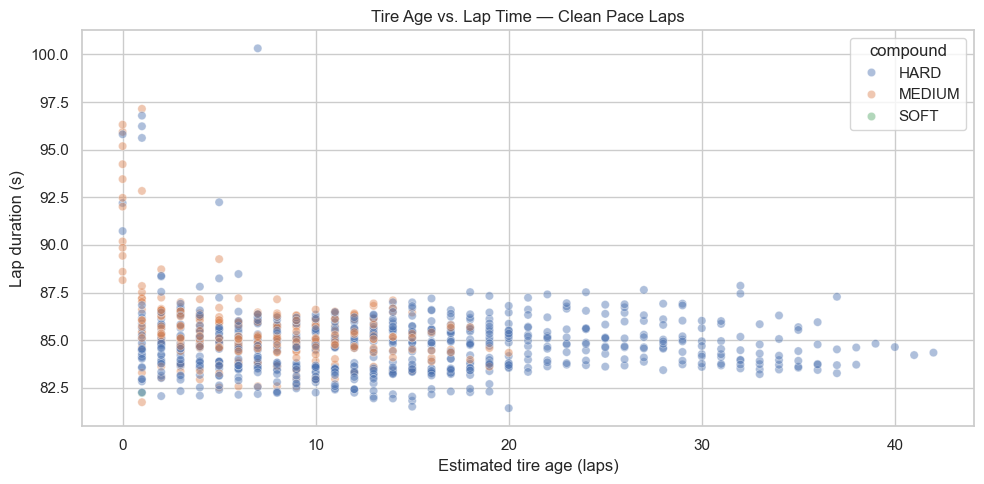

In [13]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.scatterplot(data=clean, x="tyre_age", y="lap_duration", hue="compound", alpha=0.45, ax=ax)
ax.set(title="Tire Age vs. Lap Time — Clean Pace Laps", xlabel="Estimated tire age (laps)", ylabel="Lap duration (s)")
plt.tight_layout()
plt.show()

We see that tire does increase lap time but its not very clear with this plot. Other factors are not being factoring in like the loss of fuel or other factors which could also change the lap time. The main conclusion is that tire degrdation does effect lap times. 

Plot 2 — Lap-time distribution by compound

A box plot compares observed variability. Check counts: a compound with very few laps cannot support a strong conclusion.

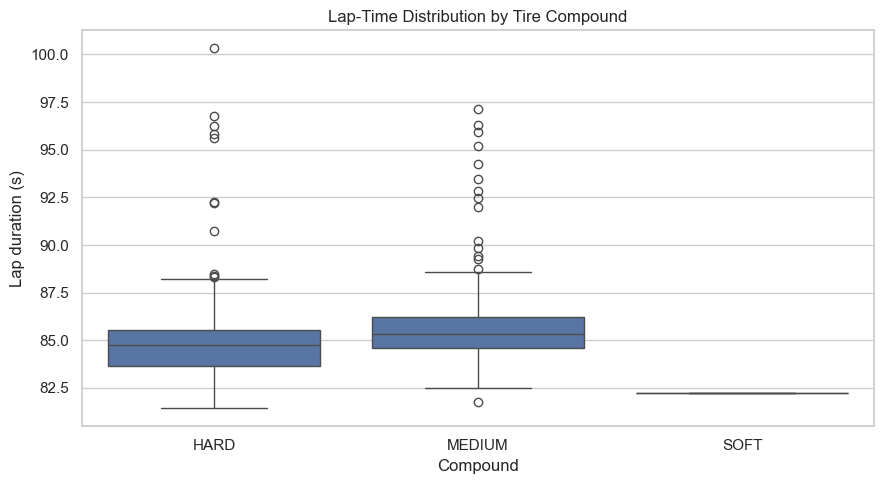

,count,mean,median,std
compound,,,,
HARD,693,84.76,84.75,1.68
MEDIUM,254,85.65,85.34,2.12
SOFT,1,82.23,82.23,NaN


In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=clean, x="compound", y="lap_duration", ax=ax)
ax.set(title="Lap-Time Distribution by Tire Compound", xlabel="Compound", ylabel="Lap duration (s)")
plt.tight_layout()
plt.show()
display(clean.groupby("compound")["lap_duration"].agg(["count", "mean", "median", "std"]).round(2))

We see that hard has the best overall tires with the lowest median but MEDIUM compound could be better in certain conditions which would require further analysis as seen with the outliers

Plot 3 — Median lap time by tire age

Also plot sample size so that sparsely observed tire ages are not overinterpreted.

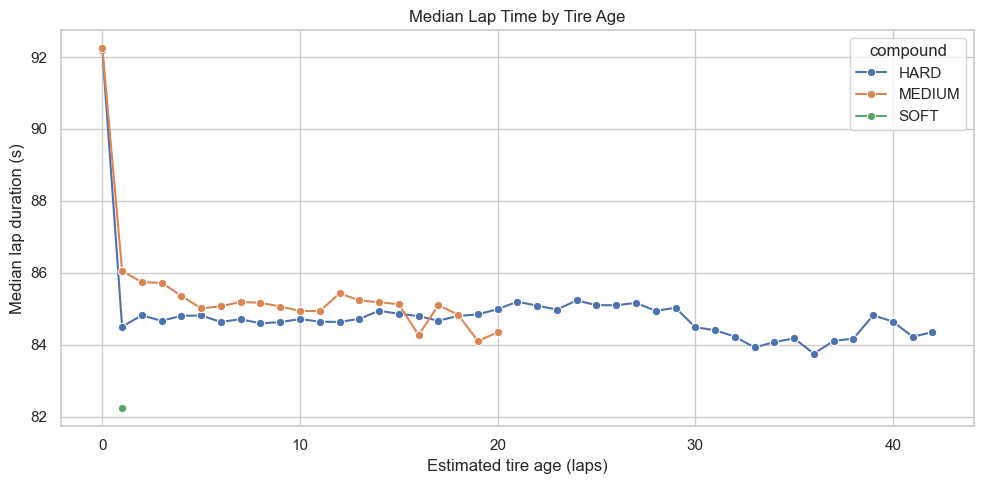

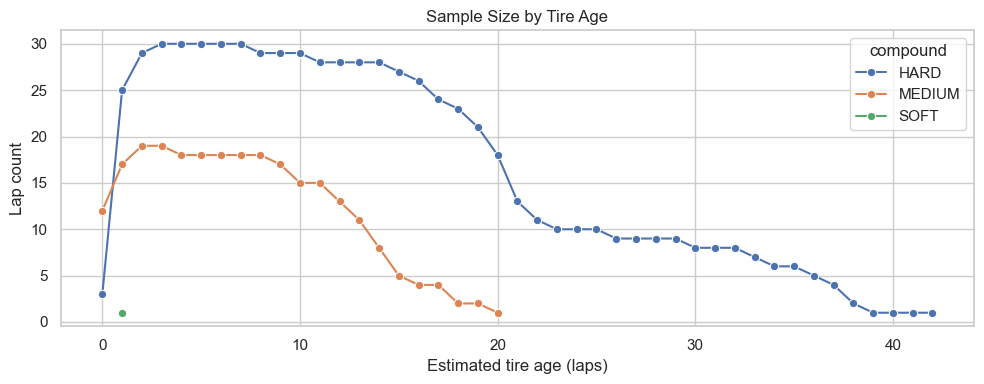

In [8]:
age_stats = clean.groupby(["compound", "tyre_age"], as_index=False).agg(
    median_lap=("lap_duration", "median"), n=("lap_duration", "size")
)
fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(data=age_stats, x="tyre_age", y="median_lap", hue="compound", marker="o", estimator=None, ax=ax)
ax.set(title="Median Lap Time by Tire Age", xlabel="Estimated tire age (laps)", ylabel="Median lap duration (s)")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
sns.lineplot(data=age_stats, x="tyre_age", y="n", hue="compound", marker="o", estimator=None, ax=ax)
ax.set(title="Sample Size by Tire Age", xlabel="Estimated tire age (laps)", ylabel="Lap count")
plt.tight_layout()
plt.show()

In the first plot we see that tire performance stayed relatively stable but 30 laps onwards showed signs of possible performance loss due to tire age but would require more data and possible other factors for stronger conclusions

In the second plot we see that hard tires generally perform better but due to the lack of observations for medium and soft tires I can't be fully confident in this conclusion

Plot 4 — Driver pace across the race

Select one driver to see where lap-time spikes occur and where pit visits were recorded.

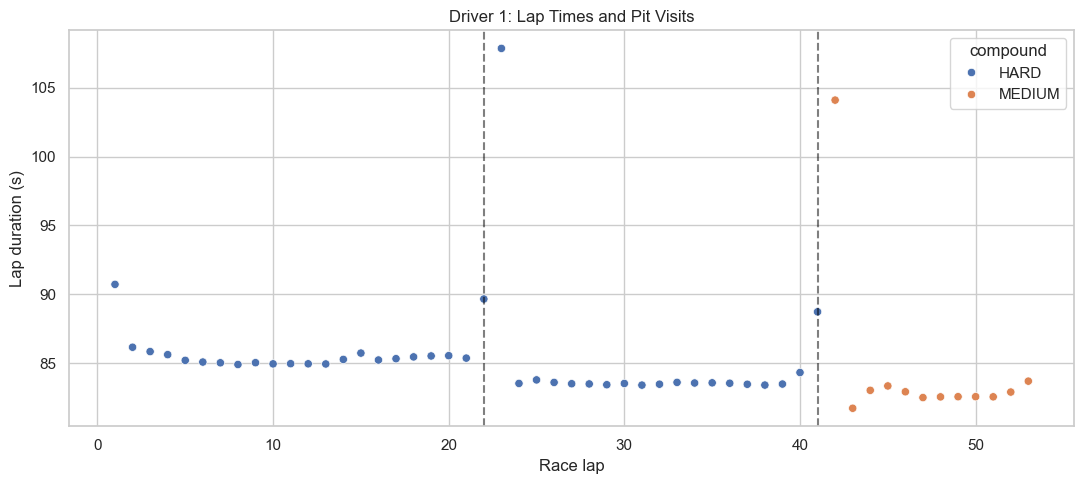

In [9]:
driver_numbers = sorted(clean["driver_number"].dropna().astype(int).unique())
if driver_numbers:
    DRIVER = driver_numbers[0]  # Change to a specific number, e.g. 16, 44, or 1
    driver_all = laps_with_tires[laps_with_tires["driver_number"] == DRIVER].sort_values("lap_number")
    driver_pits = pits[pits["driver_number"] == DRIVER] if "driver_number" in pits else pd.DataFrame()
    fig, ax = plt.subplots(figsize=(11, 5))
    sns.scatterplot(data=driver_all, x="lap_number", y="lap_duration", hue="compound", ax=ax)
    if "lap_number" in driver_pits:
        for lap in driver_pits["lap_number"].dropna():
            ax.axvline(lap, color="black", linestyle="--", alpha=0.5)
    ax.set(title=f"Driver {DRIVER}: Lap Times and Pit Visits", xlabel="Race lap", ylabel="Lap duration (s)")
    plt.tight_layout()
    plt.show()
else:
    print("No driver has clean laps.")

We see that during a pit stop really slows down the driver but we see a general decrease in lap times due to the fresh tires which could indicate that lost time could be made up with more fresh tires but other factors could lead to this.

(the higher lap time after the pit stop (dotted line) is due pit out lap which they have to exit the pit lanes)

Plot 5 — Pit-stop durations

OpenF1 fields differ across seasons. Prefer lane_duration when available and populated; stop_duration measures a different part of the stop. Pit-lane duration is not the same as net time lost relative to a normal racing lap.

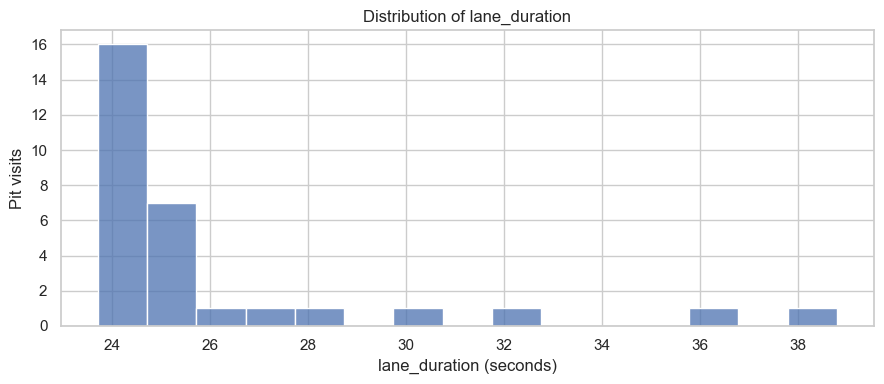

,seconds
count,30.00
mean,26.10
std,3.70
min,23.70
25%,24.22
50%,24.65
75%,25.50
max,38.80


In [10]:
duration_col = next(
    (c for c in ["lane_duration", "pit_duration", "stop_duration"]
     if c in pits and pd.to_numeric(pits[c], errors="coerce").notna().any()),
    None
)
if duration_col:
    valid_pits = pits[pits[duration_col].notna() & (pits[duration_col] > 0)].copy()
    if not valid_pits.empty:
        fig, ax = plt.subplots(figsize=(9, 4))
        sns.histplot(valid_pits[duration_col], bins=min(20, max(5, len(valid_pits)//2)), ax=ax)
        ax.set(title=f"Distribution of {duration_col}", xlabel=f"{duration_col} (seconds)", ylabel="Pit visits")
        plt.tight_layout()
        plt.show()
        display(valid_pits[duration_col].describe().round(2).to_frame("seconds"))
    else:
        print("No positive pit durations to plot.")
else:
    print("Pit durations not present; skip this plot.")

we see the majority of pit stops are around 25 seconds but sometimes most are longer due to other factors or more serious problems and pit crews messing up

Plot 6 — Pace before vs. after each pit

Compare the median of up to three clean laps before and three clean laps after each pit, excluding the pit lap and first lap afterward. These are descriptive comparisons, not estimates of causal pit-stop benefit; fuel, traffic, and compound may also change.

,driver_number,pit_lap,before_median,after_median,change_seconds
0,27,5,86.54,85.35,-1.19
1,10,10,86.46,85.07,-1.40
2,63,11,85.22,84.55,-0.67
3,3,11,85.99,85.83,-0.17
4,14,12,85.83,84.67,-1.16
5,4,14,84.66,84.15,-0.50
6,20,14,86.14,85.64,-0.50
7,16,15,85.53,84.20,-1.33
8,44,15,85.33,84.83,-0.50
9,24,15,86.80,85.24,-1.56


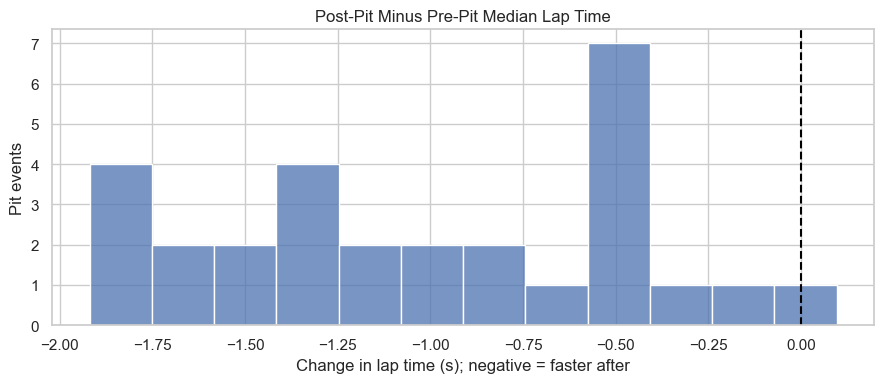

Events compared: 29


In [11]:
records = []
if {"driver_number", "lap_number"}.issubset(pits.columns):
    for _, pit in pits.dropna(subset=["driver_number", "lap_number"]).iterrows():
        d, p = pit["driver_number"], pit["lap_number"]
        g = clean[clean["driver_number"] == d]
        before = g[g["lap_number"].between(p - 3, p - 1)]["lap_duration"]
        after = g[g["lap_number"].between(p + 2, p + 4)]["lap_duration"]
        if len(before) >= 2 and len(after) >= 2:
            records.append({
                "driver_number": int(d), "pit_lap": int(p),
                "before_median": before.median(), "after_median": after.median(),
                "change_seconds": after.median() - before.median()
            })
comparison = pd.DataFrame(records)
if not comparison.empty:
    display(comparison.round(2).head(15))
    fig, ax = plt.subplots(figsize=(9, 4))
    sns.histplot(comparison["change_seconds"], bins=12, ax=ax)
    ax.axvline(0, color="black", linestyle="--")
    ax.set(title="Post-Pit Minus Pre-Pit Median Lap Time",
           xlabel="Change in lap time (s); negative = faster after", ylabel="Pit events")
    plt.tight_layout()
    plt.show()
    print("Events compared:", len(comparison))
else:
    print("Insufficient clean laps around recorded pit visits to compare.")

we see that most lap times get better after a pit stop as seen in the other plot which inforces that idea but other factors must be made to get stronger conclusions

Main findings:

- tire degradation is not very clear

- pit stops yield faster lap times

- stops cost alot of time

Important limitations: fuel burn, traffic, safety cars, weather, driver pace, and unequal tire-compound sample sizes.
